So far:

*   Fitting a regression model
*   $R^2$ and Residuals

Next:
* Multilinear Regression
* Nominal and Ordinal features
* Interaction of features

Multiple Linear Regression models the linear relationship between a continuous scalar response variable $y$ and $p$ explanatory predictor variables $x_1, x_2, \dots, x_p$.

### A. The Algebraic Equation

For an individual observation $i \in \{1, 2, \dots, n\}$:

$$y_i = \beta_0 + \beta_1 x_{i,1} + \beta_2 x_{i,2} + \dots + \beta_p x_{i,p} + \epsilon_i$$

Where:

* $\beta_0$: **Intercept** — Expected value of $y$ when all predictors $x_j = 0$.
* $\beta_j$: **Partial Regression Coefficient** — Expected change in $y$ for a 1-unit increase in $x_j$, holding all other predictors constant.
* $\epsilon_i$: **Unobserved Error Term** — Difference between observed $y_i$ and predicted value $\hat{y}_i$.

---

### B. Matrix Form & Ordinary Least Squares (OLS)

For all $n$ observations, we write:

$$Y = X\beta + \epsilon$$

Where:

$$Y = \begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_n \end{bmatrix}, \quad X = \begin{bmatrix} 1 & x_{1,1} & \dots & x_{1,p} \\ 1 & x_{2,1} & \dots & x_{2,p} \\ \vdots & \vdots & \ddots & \vdots \\ 1 & x_{n,1} & \dots & x_{n,p} \end{bmatrix}, \quad \beta = \begin{bmatrix} \beta_0 \\ \beta_1 \\ \vdots \\ \beta_p \end{bmatrix}, \quad \epsilon = \begin{bmatrix} \epsilon_1 \\ \epsilon_2 \\ \vdots \\ \epsilon_n \end{bmatrix}$$

OLS minimizes the Sum of Squared Residuals ($\text{SSR}$):

$$\text{SSR}(\beta) = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 = (Y - X\beta)^T (Y - X\beta)$$

Differentiating with respect to $\beta$ and setting to zero yields the **Normal Equations**:

$$(X^T X)\hat{\beta} = X^T Y \implies \hat{\beta} = (X^T X)^{-1} X^T Y$$

---

### C. The Gauss-Markov Assumptions

The OLS estimator $\hat{\beta}$ is the **Best Linear Unbiased Estimator** if the following conditions hold:

1. **Linearity:** The relationship between predictors and the mean response is linear in parameters.
2. **Independence:** $E[\epsilon \mid X] = 0$ (errors have zero conditional mean).
3. Constant error variance, $\text{Var}(\epsilon_i \mid X) = \sigma^2$.
4. **No Multicollinearity:** $X$ has full column rank; no predictor is a perfect linear combination of others.
5. **Normality of Errors (for inference):** $\epsilon \sim \mathcal{N}(0, \sigma^2 I)$.

---

## Modeling Different Feature Types

### A. Continuous Features

Continuous inputs (e.g., `Years_Experience`, `Square_Feet`) have a straightforward slope interpretation:

$$\hat{y} = \beta_0 + \beta_1 (\text{Experience})$$

* Interpretation: Each additional year of experience increases the predicted salary by $\beta_1$ units, holding all other variables constant.

---

### B. Categorical Features (Dummy / Indicator Variables)

Categorical features with $K$ categories require creation of $K-1$ binary indicator columns to prevent the "dummy variable trap" (perfect multicollinearity).

#### Example: Degree Level (`Bachelor`, `Master`, `PhD`)

Reference Category: `Bachelor` ($x_1=0, x_2=0$)

$$\hat{y} = \beta_0 + \beta_1 \cdot I_{\text{Master}} + \beta_2 \cdot I_{\text{PhD}}$$

| Group | $I_{\text{Master}}$ | $I_{\text{PhD}}$ | Predicted Mean Response $\hat{y}$ |
| --- | --- | --- | --- |
| **Bachelor (Reference)** | $0$ | $0$ | $\beta_0$ |
| **Master** | $1$ | $0$ | $\beta_0 + \beta_1$ |
| **PhD** | $0$ | $1$ | $\beta_0 + \beta_2$ |

* $\beta_1$: Expected average difference in $y$ between a `Master` holder and a `Bachelor` holder.
* $\beta_2$: Expected average difference in $y$ between a `PhD` holder and a `Bachelor` holder.

---

### C. Ordinal Features

Ordinal features have a clear ranking (e.g., `Satisfaction_Level`: $1, 2, 3, 4, 5$).

* **Approach 1 (Treated as Continuous):** Assumes distance between categories is equal (e.g., distance between 1 and 2 equals distance between 4 and 5).
* **Approach 2 (Treated as Categorical/Dummy Encoders):** Models arbitrary step distances between ranks without forcing linear progression (recommended if rank intervals are non-equidistant).

---

### D. Non-Linear & Power Transformations

Linear regression models parameters linearly, but inputs can be non-linearly transformed:

#### 1. Polynomial Terms

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2$$

#### 2. Logarithmic Transformations

* **Log-Linear ($y$ log-transformed):** $\ln(y) = \beta_0 + \beta_1 x \implies$ a $1$-unit increase in $x$ changes $y$ by approximately $(\beta_1 \times 100)\%$.
* **Log-Log (Both transformed):** $\ln(y) = \beta_0 + \beta_1 \ln(x) \implies$ a $1\%$ increase in $x$ leads to a $\beta_1\%$ change in $y$ (constant elasticity).

---

## Modeling Interaction Effects

An interaction occurs when the effect of predictor $X_1$ on response $Y$ depends on the level of another predictor $X_2$.

### Case 1: Continuous $\times$ Continuous Interaction

$$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 (X_1 \cdot X_2) + \epsilon$$

To interpret the marginal effect of $X_1$ on $y$, take the partial derivative with respect to $X_1$:

$$\frac{\partial y}{\partial X_1} = \beta_1 + \beta_3 X_2$$

* The slope of $X_1$ is no longer fixed at $\beta_1$; it varies dynamically as a linear function of $X_2$.
* $\beta_3$: Incremental change in the slope of $X_1$ per unit increase in $X_2$.

---

### Case 2: Continuous $\times$ Categorical Interaction (Differing Slopes)

Predicting `Salary` ($y$) from `Experience` ($X_1$, continuous) and `Management_Role` ($D \in \{0, 1\}$, categorical):

$$y = \beta_0 + \beta_1 (\text{Experience}) + \beta_2 (\text{Management}) + \beta_3 (\text{Experience} \cdot \text{Management}) + \epsilon$$

#### Model Breakdown by Group:

1. **Non-Managers ($D = 0$):**

$$\hat{y} = \beta_0 + \beta_1 (\text{Experience})$$


* Intercept = $\beta_0$, Slope = $\beta_1$


2. **Managers ($D = 1$):**

$$\hat{y} = (\beta_0 + \beta_2) + (\beta_1 + \beta_3) (\text{Experience})$$


* Intercept = $\beta_0 + \beta_2$, Slope = $\beta_1 + \beta_3$



```
Salary ($)
   ^
   |                           /  Managers (Slope = β₁ + β₃)
   |                          /
   |                         /
   |------------------------/--- Non-Managers (Slope = β₁)
   |                       /
   +--------------------------------------> Years of Experience

```

* $\beta_2$: Shift in starting intercept for managers vs. non-managers.
* $\beta_3$: **Difference in return on experience (slope difference)** between managers and non-managers.

---

### Case 3: Categorical $\times$ Categorical Interaction

When two categorical features interact (e.g., `Gender` $\times$ `Department`), the interaction term measures whether group differentials in one variable depend on group assignments in another.

---

## Statistical Diagnostics & Model Evaluation

### A. Assessing Model Performance

#### Coefficient of Determination ($R^2$)

Proportion of variance in $y$ explained by model predictors:

$$R^2 = 1 - \frac{\text{SSR}}{\text{SST}} = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

* **Issue:** $R^2$ monotonically increases whenever a new feature is added, even if the feature contains zero true predictive power.

#### Adjusted $R^2$

Penalizes model complexity (number of parameters $p$ relative to sample size $n$):

$$R^2_{\text{adj}} = 1 - \left[ (1 - R^2) \frac{n - 1}{n - p - 1} \right]$$

---

### B. Hypothesis Testing

#### 1. Individual Coefficient Significance ($t$-test)

* **Null Hypothesis:** $H_0: \beta_j = 0$ (predictor $j$ has no linear association with $y$).
* **Test Statistic:**

$$t = \frac{\hat{\beta}_j - 0}{\text{SE}(\hat{\beta}_j)} \sim t_{n - p - 1}$$


* If $p\text{-value} < \alpha$ (typically $0.05$), reject $H_0$.

#### 2. Overall Model Significance ($F$-test)

* **Null Hypothesis:** $H_0: \beta_1 = \beta_2 = \dots = \beta_p = 0$ (all slope coefficients equal zero).
* **Test Statistic:**

$$F = \frac{(\text{SST} - \text{SSR}) / p}{\text{SSR} / (n - p - 1)} \sim F_{p, \, n - p - 1}$$



---

### C. Multicollinearity & Variance Inflation Factor (VIF)

Multicollinearity occurs when two or more independent variables are highly correlated. It inflates standard errors ($\text{SE}(\hat{\beta}_j)$), making estimates unstable and $p$-values unreliable.

#### Variance Inflation Factor (VIF)

Quantifies inflation in variance for estimate $\hat{\beta}_j$:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

Where $R_j^2$ is the coefficient of determination from regressing predictor $x_j$ against all remaining predictors.

* **$\text{VIF}_j = 1$:** No collinearity.
* **$\text{VIF}_j > 5 \text{ or } 10$:** High multicollinearity requiring remediation (e.g., dropping redundant features or applying PCA/Ridge Regression).

---

### D. Residual Diagnostics

Residuals $e_i = y_i - \hat{y}_i$ must be visually inspected using standard diagnostic plots:

| Plot | Target Condition | Violation Indicator |
| --- | --- | --- |
| **Residuals vs. Fitted** | Points scattered randomly around $y=0$ baseline. | Funnel shape or non-linear curve (Misspecified functional form). |
| **Normal Q-Q Plot** | Residual quantiles align tightly along $45^\circ$ reference line. | Severe curvature at tails (heavy-tailed or non-normal error distribution). |
| **Scale-Location Plot** | Flat trendline with uniformly spread points. | Ascending or descending slope (changing variance). |
| **Residuals vs. Leverage** | No points exceed Cook's distance boundaries ($D_i > 0.5$). | Outliers with high leverage drastically influencing regression slopes. |

---


Example with statsmodel

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# 1. Generate Synthetic Dataset
np.random.seed(42)
n = 200

experience = np.random.uniform(1, 15, size=n)
management = np.random.choice([0, 1], size=n, p=[0.6, 0.4])
education = np.random.choice(['Bachelor', 'Master', 'PhD'], size=n, p=[0.5, 0.3, 0.2])

# True Data Generating Process (DGP)
# Base salary = 45000 + 3500*Exp + 10000*Mgmt + 2500*(Exp * Mgmt) + Educ_Bonus + noise
educ_effect = {'Bachelor': 0, 'Master': 8000, 'PhD': 18000}
educ_bonus = np.array([educ_effect[e] for e in education])

noise = np.random.normal(0, 4000, size=n)
salary = 45000 + (3500 * experience) + (10000 * management) + (2500 * experience * management) + educ_bonus + noise

In [3]:
df = pd.DataFrame({
    'Salary': salary,
    'Experience': experience,
    'Management': management,
    'Education': education
})

In [4]:
# 2. Fit OLS Model with Categorical variables & Interaction Terms
# Patsy Formula: C() handles categorical encoding automatically
# Experience:Management creates main effects AND continuous-by-binary interaction
formula = 'Salary ~ Experience * Management + C(Education, Treatment(reference="Bachelor"))'

model = smf.ols(formula=formula, data=df).fit()

# 3. Print Statistical Regression Summary
print(model.summary())

# 4. Check Multicollinearity using VIF
X_matrix = model.model.exog
vif_data = pd.DataFrame({
    "Feature": model.model.exog_names,
    "VIF": [variance_inflation_factor(X_matrix, i) for i in range(X_matrix.shape[1])]
})
print("\n--- Variance Inflation Factor (VIF) ---")
print(vif_data)

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.973
Model:                            OLS   Adj. R-squared:                  0.972
Method:                 Least Squares   F-statistic:                     1383.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.33e-149
Time:                        10:17:31   Log-Likelihood:                -1943.6
No. Observations:                 200   AIC:                             3899.
Df Residuals:                     194   BIC:                             3919.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                              coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------

More examples from slides

# **Regularization and Cross Validation**

## The Bias-Variance Tradeoff & Why OLS Fails

Ordinary Least Squares (OLS) produces unbiased estimates ($\text{Bias}(\hat{\beta}) = 0$) with minimum variance among all unbiased linear estimators. However, **unbiasedness does not guarantee low total error**.

### A. Mean Squared Error (MSE) Decomposition

The expected test Mean Squared Error for a model prediction $\hat{y} = \hat{f}(x)$ can be decomposed into three fundamental components:

$$\text{MSE}(\hat{y}) = \mathbb{E}\left[(y - \hat{y})^2\right] = \underbrace{\left(\text{Bias}\left[\hat{f}(x)\right]\right)^2}_{\text{Systematic Error}} + \underbrace{\text{Var}\left[\hat{f}(x)\right]}_{\text{Sensitivity to Noise}} + \underbrace{\sigma^2}_{\text{Irreducible Error}}$$

```
  High Error ^
             |       Total Test Error  /
             |         \              /   High Variance
             |          \  Optimal   /   (Overfitting)
             |           \    v     /
             |            \_______/
             |  High Bias  \_____/
             | (Underfitting)
             +-------------------------------------> Model Complexity

```

### B. The Failure Modes of OLS

1. **Multicollinearity:** When predictor columns in matrix $X$ are highly correlated, $(X^T X)$ becomes nearly singular (ill-conditioned). Small perturbations in $Y$ cause massive fluctuations in $\hat{\beta} = (X^T X)^{-1} X^T Y$, spiking model variance.
2. **High-Dimensional Settings ($p > n$):** When the number of features $p$ exceeds the number of observations $n$, $X^T X$ is no longer full rank and cannot be inverted. OLS yields infinitely many non-unique solutions with infinite variance.

**Regularization Strategy:** Introduce a deliberate statistical bias by penalizing large coefficient magnitudes. By accepting a tiny increase in bias, we drastically reduce parameter variance, achieving a lower overall test MSE.

---


### A. Ridge Regression ($L_2$ Penalty)

Ridge regression adds a quadratic penalty on the magnitude of the coefficient vector $\beta$:

$$\min_{\beta} \left\{ \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 + \lambda \sum_{j=1}^{p} \beta_j^2 \right\} = \min_{\beta} \left\{ \Vert{}Y - X\beta\Vert{}_2^2 + \lambda \Vert{}\beta\Vert{}_2^2 \right\}$$

Where $\lambda \ge 0$ is the **tuning hyperparameter** (note: represented as `alpha` in Scikit-Learn):

This is a.k.a. *Constrained optimisation*

* When $\lambda = 0$: Objective reduces to standard OLS.
* As $\lambda \to \infty$: Penalty dominates; all slopes $\beta_j \to 0$ (intercept $\beta_0$ remains unpenalized).

#### Closed-Form Analytical Solution

Unlike Lasso, Ridge retains a closed-form matrix solution:

$$\hat{\beta}_{\text{Ridge}} = (X^T X + \lambda I)^{-1} X^T Y$$

> Adding $\lambda I$ (where $I$ is the identity matrix) adds a positive constant to the diagonal of $X^T X$. This guarantees that $(X^T X + \lambda I)$ is strictly non-singular and invertible, even when $p > n$ or features are collinear!

---

### B. Lasso Regression ($L_1$ Penalty)

Lasso (Least Absolute Shrinkage and Selection Operator) replaces the squared penalty with an absolute value penalty:

$$\min_{\beta} \left\{ \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 + \lambda \sum_{j=1}^{p} \vert{}\beta_j\vert{} \right\} = \min_{\beta} \left\{ \Vert{}Y - X\beta\Vert{}_2^2 + \lambda \Vert{}\beta\Vert{}_1 \right\}$$

#### Features of Lasso:

* **No Closed-Form Matrix Solution:** Solved computationally using **Coordinate Descent** or **Subgradient Optimization**.
* **Sparsity & Automatic Feature Selection:** For sufficiently large values of $\lambda$, Lasso forces uninformative feature coefficients strictly to **zero** ($\beta_j = 0$), performing built-in variable selection.

---

### C. Elastic Net Regression

Elastic Net combines both $L_1$ and $L_2$ penalties using two hyperparameters ($\lambda$ for strength, $\alpha$ for mix ratio):

$$\min_{\beta} \left\{ \Vert{}Y - X\beta\Vert{}_2^2 + \lambda \left[ \alpha \Vert{}\beta\Vert{}_1 + \frac{1 - \alpha}{2} \Vert{}\beta\Vert{}_2^2 \right] \right\}$$

* **Why Use Elastic Net?** When multiple features are highly correlated in groups, Lasso tends to pick one feature at random and set the rest to zero. Elastic Net maintains the sparsity of Lasso while sharing penalty weight across correlated feature groups like Ridge.

---

**Critical Rule of Regularization:** Features **MUST** be standardized ($\mu=0, \sigma=1$) before applying Ridge or Lasso! Unscaled features with large numerical ranges (e.g., `Income` in dollars vs `Age` in years) would penalize the slope of `Age` disproportionately.

###EXAMPLE: Ridge
When predictors are strongly correlated, standard OLS produces unstable coefficient estimates with inflated variances. Ridge makes the coefficient uniform over different colinear features.

In [13]:
import numpy as np
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler

# Generate collinear features
np.random.seed(42)
x1 = np.random.uniform(1, 10, 50)
x2 = x1 * 0.98 + np.random.normal(0, 0.1, 50)  # ~98% correlated with x1
y = 3 * x1 + 2 * x2 + np.random.normal(0, 2, 50)

X = StandardScaler().fit_transform(np.column_stack([x1, x2]))

# Fit OLS vs Ridge
ols = LinearRegression().fit(X, y)
ridge = Ridge(alpha=10.0).fit(X, y)

print(f"OLS Coefficients:   x1 = {ols.coef_[0]:.2f},  x2 = {ols.coef_[1]:.2f}")
print(f"Ridge Coefficients: x1 = {ridge.coef_[0]:.2f},  x2 = {ridge.coef_[1]:.2f}")

OLS Coefficients:   x1 = 16.89,  x2 = -3.72
Ridge Coefficients: x1 = 6.02,  x2 = 5.95


### Example: LASSO
A dataset contains $10$ features, but only $3$ actually influence the target variable $y$. The remaining $7$ are noise.

In [17]:
from sklearn.datasets import make_regression
from sklearn.linear_model import Lasso

# Generate 10 features, only 3 are informative
X_sparse, y_sparse = make_regression(
    n_samples=100, n_features=10, n_informative=3, noise=10.0, random_state=42
)
X_scaled = StandardScaler().fit_transform(X_sparse)

ols_sparse = LinearRegression().fit(X_scaled, y_sparse)
lasso_sparse = Lasso(alpha=3.0).fit(X_scaled, y_sparse)

print("OLS Coefficients:\n", np.round(ols_sparse.coef_, 2))
print("\nLasso Coefficients (alpha=3.0):\n", np.round(lasso_sparse.coef_, 2))

OLS Coefficients:
 [14.9   0.55  0.63 64.54  1.71  0.13 -0.99  9.54  0.38 -1.24]

Lasso Coefficients (alpha=3.0):
 [12.01  0.   -0.   61.85  0.   -0.   -0.    6.64  0.   -0.  ]


**How coefficients reduce as regularisation strength increases**

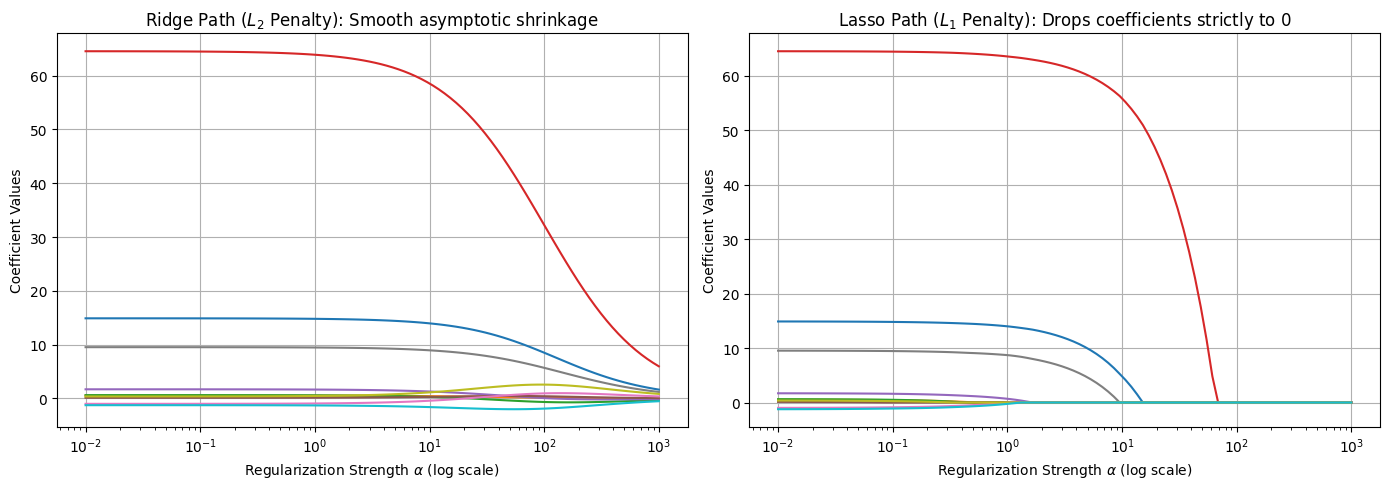

In [18]:
import matplotlib.pyplot as plt

alphas = np.logspace(-2, 3, 100)
ridge_coefs, lasso_coefs = [], []

for a in alphas:
    r = Ridge(alpha=a).fit(X_scaled, y_sparse)
    l = Lasso(alpha=a).fit(X_scaled, y_sparse)
    ridge_coefs.append(r.coef_)
    lasso_coefs.append(l.coef_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ridge Path
axes[0].plot(alphas, ridge_coefs)
axes[0].set_xscale('log')
axes[0].set_xlabel(r'Regularization Strength $\alpha$ (log scale)')
axes[0].set_ylabel('Coefficient Values')
axes[0].set_title(r'Ridge Path ($L_2$ Penalty): Smooth asymptotic shrinkage')
axes[0].grid(True)

# Lasso Path
axes[1].plot(alphas, lasso_coefs)
axes[1].set_xscale('log')
axes[1].set_xlabel(r'Regularization Strength $\alpha$ (log scale)')
axes[1].set_ylabel('Coefficient Values')
axes[1].set_title(r'Lasso Path ($L_1$ Penalty): Drops coefficients strictly to 0')
axes[1].grid(True)

plt.tight_layout()
plt.show()

#CROSS VALIDATION

How do we choose the optimal regularization strength $\lambda$? We cannot tune $\lambda$ on the training set because increasing $\lambda$ always increases training error. Solution: **Cross-Validation (CV)**.

---

### A. $K$-Fold Cross-Validation

1. Split the training data into $K$ equal, non-overlapping partitions (folds).
2. For each fold $k \in \{1, 2, \dots, K\}$:
* Train the regularized model on $K-1$ folds using candidate $\lambda$.
* Compute test performance metric ($\text{MSE}_k$) on the $k$-th validation fold.


3. Average validation errors across all $K$ iterations:

$$\text{CV}_{(K)}(\lambda) = \frac{1}{K} \sum_{k=1}^{K} \text{MSE}_k(\lambda)$$

4. Select $\lambda$ that minimizes $\text{CV}_{(K)}(\lambda)$.

---

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Synthesize Synthetic Dataset with Collinear Features
X_raw, y, true_coef = make_regression(
    n_samples=250, n_features=20, n_informative=5, noise=10.0, coef=True, random_state=42
)

# Introduce artificial multicollinearity (Duplicate feature 0 with minor noise)
collinear_feature = X_raw[:, [0]] * 0.98 + np.random.normal(0, 0.01, size=(250, 1))
X = np.hstack([X_raw, collinear_feature])

# Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Build Ridge Pipeline with 5-Fold Cross-Validation
alphas = np.logspace(-3, 3, 100)  # Search space: 0.001 to 1000

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', RidgeCV(alphas=alphas, cv=5, scoring='neg_mean_squared_error'))
])

ridge_pipeline.fit(X_train, y_train)
best_ridge_alpha = ridge_pipeline.named_steps['ridge'].alpha_
y_pred_ridge = ridge_pipeline.predict(X_test)

# 3. Build Lasso Pipeline with 5-Fold Cross-Validation
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42))
])

lasso_pipeline.fit(X_train, y_train)
best_lasso_alpha = lasso_pipeline.named_steps['lasso'].alpha_
lasso_coefs = lasso_pipeline.named_steps['lasso'].coef_
y_pred_lasso = lasso_pipeline.predict(X_test)

# 4. Model Evaluation & Comparison
print("--- MODEL PERFORMANCE EVALUATION ---")
print(f"Optimal Ridge Alpha: {best_ridge_alpha:.4f}")
print(f"Ridge Test R2 Score: {r2_score(y_test, y_pred_ridge):.4f}")
print(f"\nOptimal Lasso Alpha: {best_lasso_alpha:.4f}")
print(f"Lasso Test R2 Score: {r2_score(y_test, y_pred_lasso):.4f}")
print(f"Total Initial Features: {X_train.shape[1]}")
print(f"Lasso Retained Features (Non-Zero): {np.sum(lasso_coefs != 0)}")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 128.7663618555125, tolerance: 67.36802681101112
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 158.80732563419224, tolerance: 67.36802681101112
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 172.0137185544918, tolerance: 67.36802681101112
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWa

--- MODEL PERFORMANCE EVALUATION ---
Optimal Ridge Alpha: 1.0723
Ridge Test R2 Score: 0.9706

Optimal Lasso Alpha: 0.9326
Lasso Test R2 Score: 0.9728
Total Initial Features: 21
Lasso Retained Features (Non-Zero): 7


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 159.98385736609998, tolerance: 73.78290311650812
  model = cd_fast.enet_coordinate_descent_gram(



## Empirical vs. Generalization Risk

In supervised learning, our objective is to find a hypothesis function $\hat{f}(x)$ trained on dataset $D = \{(x_1, y_1), (x_2, y_2), \dots, (x_N, y_N)\}$ that minimizes error on unseen samples drawn from the underlying joint data distribution $P(X, Y)$.

### A. Empirical Risk (Training Error)

The mean performance evaluated directly on the $N$ samples used to fit model parameters:

$$E_{\text{train}} = \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{f}(x_i))$$

Where $L(y, \hat{y})$ is the loss metric (e.g., Mean Squared Error $L(y, \hat{y}) = (y - \hat{y})^2$).

---

### B. Generalization Risk (Validation / Test Error)

The expected performance evaluated on an independent validation set $D_{\text{val}}$ of size $M$ that was completely withheld during model training:

$$E_{\text{val}} = \frac{1}{M} \sum_{j=1}^{M} L(y_j, \hat{f}(x_j))$$

---

### C. The Generalization Gap

The difference between training error and validation error defines the **Generalization Gap**:

$$\text{Generalization Gap} = E_{\text{val}} - E_{\text{train}}$$

* **Small Gap + High $E_{\text{train}}$:** Model is failing to fit the training data (**Underfitting / High Bias**).


* **Large Gap + Low $E_{\text{train}}$:** Model memorizes training noise but fails to generalize (**Overfitting / High Variance**).

---

## Validation Curves: Error vs. Model Complexity

A **Validation Curve** plots both $E_{\text{train}}$ and $E_{\text{val}}$ as a function of model hyperparameter capacity $d$ (e.g., polynomial degree, tree depth, or the inverse of regularization strength $1/\lambda$).

```
  Error ^
        |
        |  High Bias                   Optimal                   High Variance
        | (Underfitting)             Complexity                  (Overfitting)
        |       \                        |                             /
        |        \                       |   Validation Error         /
        |         \                      |        (E_val)            /
        |          \                     v                          /
        |           \------------------.__                        /
        |                                 `---._________________./
        |          --------------------------------------------'  <-- Large Gap
        |         /                                           
        |        /                                Training Error
        |       /                                    (E_train)
        +--------------------------------------------------------------------> Model Complexity (p)

```

### Analysis across Complexity Regimes

#### 1. Underfitting Regime (Low Complexity)

* **Characteristics:** Both $E_{\text{train}}$ and $E_{\text{val}}$ are high. The generalization gap $E_{\text{val}} - E_{\text{train}}$ is narrow.
* **Cause:** The hypothesis space is too restrictive to capture underlying data structure (e.g., fitting a straight line to quadratic data).
* **Bias-Variance Profile:** **High Bias**, Low Variance.

#### 2. Optimal Complexity Regime (Sweet Spot)

* **Characteristics:** $E_{\text{val}}$ reaches its minimum value. $E_{\text{train}}$ is low, and the generalization gap remains reasonably small.
* **Cause:** Model captures true underlying patterns while ignoring sample-specific random noise.

#### 3. Overfitting Regime (High Complexity)

* **Characteristics:** $E_{\text{train}}$ continues dropping toward zero, but $E_{\text{val}}$ increases sharply. The generalization gap $E_{\text{val}} - E_{\text{train}}$ becomes wide.
* **Cause:** Model parameters fit random noise and sample fluctuations rather than true population signals.
* **Bias-Variance Profile:** Low Bias, **High Variance**.

---

## Learning Curves: Error vs. Dataset Size ($N$)

A **Learning Curve** plots $E_{\text{train}}$ and $E_{\text{val}}$ on the vertical axis against the training sample size $N$ on the horizontal axis, keeping model parameters fixed.

As $N$ increases:

* **$E_{\text{train}}$ generally increases:** It is easy for a model to fit 5 data points perfectly ($E_{\text{train}} \approx 0$), but much harder to fit 10,000 points simultaneously.
* **$E_{\text{val}}$ generally decreases:** More training samples constrain parameter estimates closer to true population parameters, improving generalization.

---

### Case A: High Bias Model (Underfitting) vs. Dataset Size $N$

When a model lacks sufficient capacity (e.g., linear regression on non-linear data):

```
  Error ^
        |
        |      Validation Error (E_val)
        |       \
        |        \______________________________________ High Error Plateau
        |        /-------------------------------------- (Both lines converge)
        |       /
        |      Training Error (E_train)
        |
        +------------------------------------------------------------> Sample Size (N)

```

#### Key Characteristics:

* $E_{\text{train}}$ rises quickly as $N$ increases.
* $E_{\text{val}}$ drops initially but rapidly plateaus at a high error level.
* Both curves converge closely to each other at a high error baseline.

> For a **High Bias** model, collecting more training data ($N \to \infty$) **will NOT help**. The error plateaus well above the target baseline because the model architecture itself is incapable of representing the function.

---

### Case B: High Variance Model (Overfitting) vs. Dataset Size $N$

When a model has high capacity (e.g., degree-10 polynomial without regularization) relative to initial data size:

```
  Error ^
        |
        |      Validation Error (E_val)
        |       \
        |        `\
        |          `\___________________________________ Lower Desirable Error
        |           | <----- Persistent Gap ------> |
        |  ----------.__________________________________
        |  E_train (Starts extremely low)
        |
        +------------------------------------------------------------> Sample Size (N)

```

#### Key Characteristics:

* At small $N$, $E_{\text{train}}$ is near zero because the model easily interpolates small sample sizes. $E_{\text{val}}$ is extremely high.
* A significant **generalization gap** remains at moderate $N$.
* As $N$ increases toward infinity, $E_{\text{train}}$ increases gradually while $E_{\text{val}}$ continues to decline, closing the gap.

> For a **High Variance** model, collecting more training data ($N \to \infty$) **IS highly effective**. Additional data constrains parameter variance and forces the complex model to generalize.

# **Guidelines**

<br>(Small Gap) | **High Bias**<br>

<br>(Underfitting) | 1. Add more features / feature interactions.<br>

<br>2. Increase model complexity (e.g., higher polynomial degree).<br>

<br>3. Decrease regularization strength ($\lambda \downarrow$). | 1. Collecting more training samples ($N$).<br>

<br>2. Increasing regularization penalty. |
| **Low $E_{\text{train}}$ & High $E_{\text{val}}$**<br>

<br>(Large Gap) | **High Variance**<br>

<br>(Overfitting) | 1. **Collect more training samples ($N$)**.<br>

<br>2. Reduce feature count (Feature selection / PCA).<br>

<br>3. Increase regularization strength ($\lambda \uparrow$).<br>

<br>4. Simplify model architecture. | 1. Adding more features.<br>

<br>2. Training for longer epochs without regularization. |

---

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.model_selection import learning_curve, validation_curve

`sklearn.pipeline`

https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

A sequence of data **transformers** with an optional final predictor.

Pipeline allows you to sequentially apply a list of transformers to preprocess the data and, if desired, conclude the sequence with a final predictor for predictive modeling.

Preprocessing & Feature Transformers: Code components and pipelines (such as Scikit-Learn transformers) that clean, scale, encode, and convert raw data matrices into structured, numerical formats suitable for algorithms.

In [7]:
# 1. Generate Synthetic Quadratic Dataset with Noise
np.random.seed(42)
N_samples = 200
X = np.sort(np.random.uniform(-3, 3, size=(N_samples, 1)), axis=0)
y = 0.5 * (X.ravel() ** 2) + X.ravel() + 2 + np.random.normal(0, 1.2, size=N_samples)

In [8]:
# 2. Compute Validation Curve (Model Complexity: Polynomial Degree 1 to 8)
degrees = np.arange(1, 9)
pipe = make_pipeline(PolynomialFeatures(), Ridge(alpha=1.0))

train_scores_val, test_scores_val = validation_curve(
    estimator=pipe,
    X=X,
    y=y,
    param_name="polynomialfeatures__degree",
    param_range=degrees,
    cv=5,
    scoring="neg_mean_squared_error"
)


In [9]:
# Convert Negative MSE to Root Mean Squared Error (RMSE)
train_rmse_val = np.sqrt(-np.mean(train_scores_val, axis=1))
test_rmse_val = np.sqrt(-np.mean(test_scores_val, axis=1))


In [10]:
# Compute Learning Curve for High Bias (Degree 1) vs High Variance (Degree 8)
def get_learning_curve(model_degree):
    model = make_pipeline(PolynomialFeatures(degree=model_degree), Ridge(alpha=0.01))
    train_sizes, train_scores, test_scores = learning_curve(
        estimator=model,
        X=X,
        y=y,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5,
        scoring="neg_mean_squared_error"
    )
    train_rmse = np.sqrt(-np.mean(train_scores, axis=1))
    test_rmse = np.sqrt(-np.mean(test_scores, axis=1))
    return train_sizes, train_rmse, test_rmse

train_sizes_underfit, train_rmse_underfit, test_rmse_underfit = get_learning_curve(model_degree=1)
train_sizes_overfit, train_rmse_overfit, test_rmse_overfit = get_learning_curve(model_degree=8)

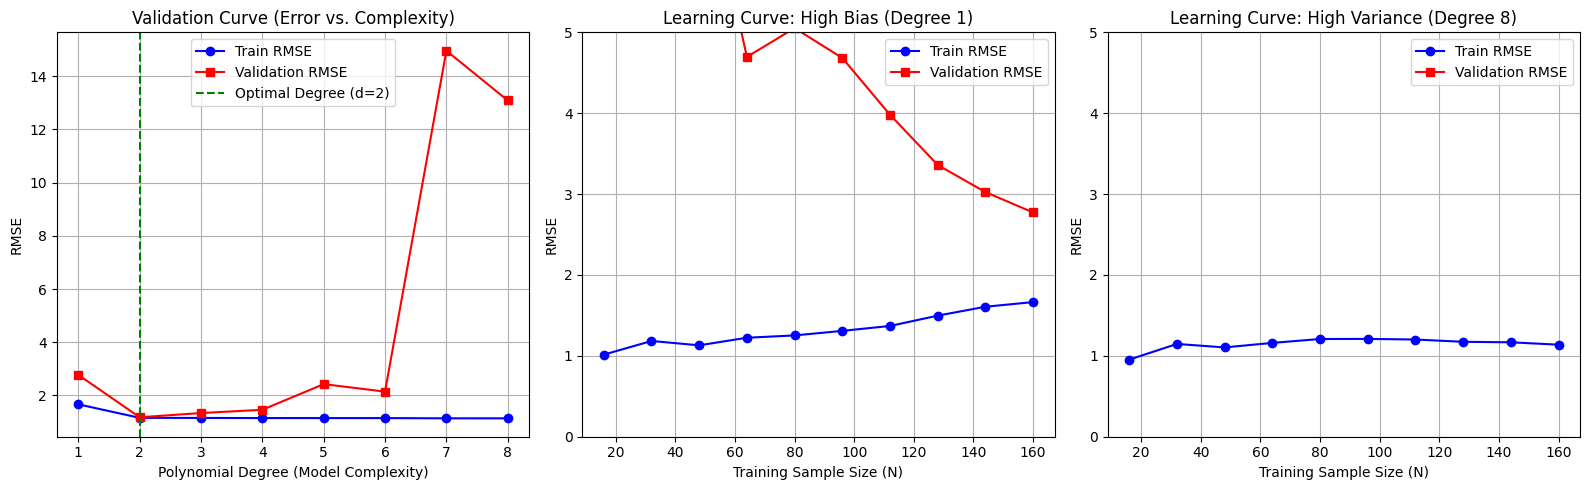

In [11]:
# Plotting Results
plt.figure(figsize=(16, 5))

# Plot A: Validation Curve
plt.subplot(1, 3, 1)
plt.plot(degrees, train_rmse_val, 'o-', color='blue', label='Train RMSE')
plt.plot(degrees, test_rmse_val, 's-', color='red', label='Validation RMSE')
plt.xlabel('Polynomial Degree (Model Complexity)')
plt.ylabel('RMSE')
plt.title('Validation Curve (Error vs. Complexity)')
plt.axvline(x=2, color='green', linestyle='--', label='Optimal Degree (d=2)')
plt.legend()
plt.grid(True)

# Plot B: Learning Curve (High Bias - Degree 1)
plt.subplot(1, 3, 2)
plt.plot(train_sizes_underfit, train_rmse_underfit, 'o-', color='blue', label='Train RMSE')
plt.plot(train_sizes_underfit, test_rmse_underfit, 's-', color='red', label='Validation RMSE')
plt.xlabel('Training Sample Size (N)')
plt.ylabel('RMSE')
plt.title('Learning Curve: High Bias (Degree 1)')
plt.ylim(0, 5)
plt.legend()
plt.grid(True)

# Plot C: Learning Curve (High Variance - Degree 8)
plt.subplot(1, 3, 3)
plt.plot(train_sizes_overfit, train_rmse_overfit, 'o-', color='blue', label='Train RMSE')
plt.plot(train_sizes_overfit, test_rmse_overfit, 's-', color='red', label='Validation RMSE')
plt.xlabel('Training Sample Size (N)')
plt.ylabel('RMSE')
plt.title('Learning Curve: High Variance (Degree 8)')
plt.ylim(0, 5)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()